# 📊 File 2: Baseline Machine Learning Pipeline (TF-IDF & Model Klasik)
**Riset Skripsi**: Perbandingan Kinerja RoBERTa-base dan DistilBERT-base untuk Deteksi Phishing URL  
- **Target Runtime**: Google Colab (CPU / GPU Environment)  
- **Storage Backend**: Google Drive (`/content/drive/MyDrive/Skripsi/`)  
- **Tujuan Utama**: Membangun tolak ukur (*benchmark*) model machine learning tradisional (Logistic Regression & LightGBM) berbasis ekstraksi fitur karakter n-gram (3-5) dan subword delimiter untuk dibandingkan dengan arsitektur Transformer.

---
### 📋 Ringkasan Alur Kerja Notebook:
1. **Setup & Google Drive Mounting**: Menghubungkan Google Drive dan memuat library ML.
2. **Pemuatan Dataset Terpisah**: Memuat `train.csv`, `val.csv`, dan `test.csv` hasil partisi domain bebas kebocoran.
3. **Ekstraksi Fitur Teks**: Menggabungkan char n-gram (3 s.d. 5) dan subword delimiter tokenizer menggunakan `FeatureUnion`.
4. **Pelatihan Model Klasik**:
   - Logistic Regression dengan regularisasi L2.
   - LightGBM Classifier (Gradient Boosting) dengan early stopping.
5. **Evaluasi Independen pada Test Set**:
   - Metrik Klasifikasi: Accuracy, Precision, Recall, F1 (Binary & Macro), ROC-AUC, PR-AUC.
   - Metrik Efisiensi Komputasi: Latensi inferensi per sampel (ms) dan Throughput (sampel/detik).
6. **Visualisasi Publikasi (300 DPI)**: Bar chart performa serta kurva ROC dan Precision-Recall berdampingan.
7. **Ekspor Hasil**: Menyimpan tabel rekapitulasi ke `/content/drive/MyDrive/Skripsi/results/baseline_comparison.csv`.


## 1. Setup Lingkungan & Instalasi Dependensi
Menginstalasi pustaka machine learning: `lightgbm`, `xgboost`, `scikit-learn`, `pandas`, `numpy`, `matplotlib`, `seaborn`.


In [1]:
# Instalasi library yang dibutuhkan di Google Colab
!pip install lightgbm xgboost scikit-learn pandas numpy tqdm matplotlib seaborn -q

import os
import sys
import gc
import time
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import FeatureUnion
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, confusion_matrix,
    roc_curve, precision_recall_curve
)
import lightgbm as lgb
from google.colab import drive

# Setup plot style
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.dpi'] = 300

print("[OK] Seluruh library machine learning berhasil diimpor.")


[OK] Seluruh library machine learning berhasil diimpor.


## 2. Mount Google Drive & Konfigurasi Direktori
Menghubungkan direktori Google Drive (`/content/drive/MyDrive/Skripsi`) dan menyiapkan jalur input serta output.


In [2]:
# 1. Mount Google Drive
print("[INFO] Melakukan mounting Google Drive...")
drive.mount('/content/drive')

# 2. Direktori Proyek
BASE_DIR = "/content/drive/MyDrive/Skripsi"
DATA_DIR = os.path.join(BASE_DIR, "new data")
if not os.path.exists(DATA_DIR):
    DATA_DIR = os.path.join(BASE_DIR, "data")

RESULTS_DIR = os.path.join(BASE_DIR, "results")
os.makedirs(RESULTS_DIR, exist_ok=True)

# 3. Path Data Split
TRAIN_PATH = os.path.join(DATA_DIR, "train.csv")
VAL_PATH = os.path.join(DATA_DIR, "val.csv")
TEST_PATH = os.path.join(DATA_DIR, "test.csv")

# 4. Target Output
OUTPUT_CSV_PATH = os.path.join(RESULTS_DIR, "baseline_comparison.csv")

print(f"[OK] Direktori Data    : {DATA_DIR}")
print(f"[OK] Direktori Hasil   : {RESULTS_DIR}")
print(f"[OK] Target Output CSV : {OUTPUT_CSV_PATH}")


Mounted at /content/drive
[OK] Direktori Data    : /content/drive/MyDrive/Skripsi/new data
[OK] Direktori Hasil   : /content/drive/MyDrive/Skripsi/results
[OK] Target Output CSV : /content/drive/MyDrive/Skripsi/results/baseline_comparison.csv


## 3. Pemuatan Dataset (Train, Validation, Test)
Membaca partisi yang telah bersih dari kebocoran domain (`train.csv`, `val.csv`, `test.csv`) dari folder data Google Drive.


In [3]:
print("[INFO] Memuat dataset Train, Val, dan Test dari Google Drive...")

for path_check, name in [(TRAIN_PATH, "train.csv"), (VAL_PATH, "val.csv"), (TEST_PATH, "test.csv")]:
    if not os.path.exists(path_check):
        raise FileNotFoundError(f"❌ File tidak ditemukan: {path_check}. Jalankan 01_Data_Prep.ipynb terlebih dahulu!")

train_df = pd.read_csv(TRAIN_PATH)
val_df = pd.read_csv(VAL_PATH)
test_df = pd.read_csv(TEST_PATH)

print(f"[OK] Train Set : {len(train_df):,} baris")
print(f"[OK] Val Set   : {len(val_df):,} baris")
print(f"[OK] Test Set  : {len(test_df):,} baris")

print("\nDistribusi Label Data Uji (Test Set):")
print(test_df['label'].value_counts())
print(test_df['label'].value_counts(normalize=True) * 100)


[INFO] Memuat dataset Train, Val, dan Test dari Google Drive...
[OK] Train Set : 927,898 baris
[OK] Val Set   : 198,052 baris
[OK] Test Set  : 222,316 baris

Distribusi Label Data Uji (Test Set):
label
0    120335
1    101981
Name: count, dtype: int64
label
0    54.127908
1    45.872092
Name: proportion, dtype: float64


## 4. Ekstraksi Fitur Teks: Char n-gram (3-5) & Subword Delimiter Tokenizer
Membangun representasi vektor teks berkecepatan tinggi dengan `FeatureUnion`:
1. **Character n-gram Vectorizer (3 s.d. 5)**: Menangkap variasi struktur URL, subdomain acak, pemendekan URL, dan typosquatting.
2. **Subword Delimiter Vectorizer**: Memecah URL berdasarkan delimiter (`/`, `-`, `_`, `?`, `=`, `&`, `.`, `:`, `;`, `~`) untuk mengekstrak kata kunci bermakna (misal: "login", "account", "verify", "secure").
3. Menggunakan `sublinear_tf=True` dan `dtype=np.float32` untuk mengoptimalkan penggunaan memori RAM.


In [4]:
print("[INFO] Membangun FeatureUnion (Char n-gram 3-5 + Delimiter Subword Tokenizer)...")

# 1. Char n-gram Vectorizer (3 s.d. 5)
char_vectorizer = TfidfVectorizer(
    analyzer='char',
    ngram_range=(3, 5),
    max_features=60000,
    min_df=5,
    sublinear_tf=True,
    dtype=np.float32
)

# 2. Delimiter Subword Vectorizer
delimiter_pattern = r'[^/\-_?=&.:;~\s]+'
word_vectorizer = TfidfVectorizer(
    analyzer='word',
    token_pattern=delimiter_pattern,
    ngram_range=(1, 2),
    max_features=25000,
    min_df=5,
    sublinear_tf=True,
    dtype=np.float32
)

# 3. Gabungkan kedua representasi menggunakan FeatureUnion
feature_extractor = FeatureUnion([
    ('char_ngram', char_vectorizer),
    ('subword_delim', word_vectorizer)
], n_jobs=-1)

# Persiapkan data teks (gunakan url_norm jika tersedia, fallback ke url)
text_col = 'url_norm' if 'url_norm' in train_df.columns else 'url'
print(f"[INFO] Kolom teks yang digunakan: '{text_col}'")

X_train_raw = train_df[text_col].fillna("").astype(str)
y_train = train_df['label'].values

X_val_raw = val_df[text_col].fillna("").astype(str)
y_val = val_df['label'].values

X_test_raw = test_df[text_col].fillna("").astype(str)
y_test = test_df['label'].values

# Fit pada Train dan Transform ke Train, Val, Test
t0 = time.perf_counter()
print("[INFO] Melakukan fit dan transform pada Train Set...")
X_train = feature_extractor.fit_transform(X_train_raw)
fit_time = time.perf_counter() - t0
print(f"[OK] Fit & Transform Train selesai ({fit_time:.2f} dtk) | Matriks: {X_train.shape}")

print("[INFO] Melakukan transform pada Val dan Test Set...")
X_val = feature_extractor.transform(X_val_raw)
X_test = feature_extractor.transform(X_test_raw)
print(f"[OK] Transform Val selesai  | Matriks: {X_val.shape}")
print(f"[OK] Transform Test selesai | Matriks: {X_test.shape}")


[INFO] Membangun FeatureUnion (Char n-gram 3-5 + Delimiter Subword Tokenizer)...
[INFO] Kolom teks yang digunakan: 'url_norm'
[INFO] Melakukan fit dan transform pada Train Set...
[OK] Fit & Transform Train selesai (170.73 dtk) | Matriks: (927898, 85000)
[INFO] Melakukan transform pada Val dan Test Set...
[OK] Transform Val selesai  | Matriks: (198052, 85000)
[OK] Transform Test selesai | Matriks: (222316, 85000)


## 5. Pelatihan Model 1: Logistic Regression (L2 Regularization)
Melatih model linear Logistic Regression dengan penalti L2, solver L-BFGS teroptimasi matriks sparse, dan bobot kelas seimbang.


In [5]:
print("======================================================================")
print("🏋️ [TRAINING] Model 1: Logistic Regression (L2 Regularization)")
print("======================================================================")

lr_model = LogisticRegression(
    penalty='l2',
    C=1.0,
    solver='lbfgs',
    max_iter=1000,
    random_state=42,
    n_jobs=-1
)

t_start_lr = time.perf_counter()
lr_model.fit(X_train, y_train)
lr_train_time = time.perf_counter() - t_start_lr
print(f"[OK] Pelatihan Logistic Regression selesai dalam {lr_train_time:.2f} detik!")

# Evaluasi cepat pada Val Set
val_preds_lr = lr_model.predict(X_val)
val_acc_lr = accuracy_score(y_val, val_preds_lr)
val_f1_lr = f1_score(y_val, val_preds_lr)
print(f"[VALIDATION] LR Val Accuracy: {val_acc_lr*100:.2f}% | Val F1-Binary: {val_f1_lr:.4f}")


🏋️ [TRAINING] Model 1: Logistic Regression (L2 Regularization)
[OK] Pelatihan Logistic Regression selesai dalam 55.76 detik!
[VALIDATION] LR Val Accuracy: 92.98% | Val F1-Binary: 0.9330


## 6. Pelatihan Model 2: LightGBM Classifier (Gradient Boosting)
Melatih model Gradient Boosted Decision Tree (LightGBM) dengan early stopping berbasis validation set untuk mencegah overfitting.


In [6]:
print("======================================================================")
print("🏋️ [TRAINING] Model 2: LightGBM Classifier")
print("======================================================================")

lgb_model = lgb.LGBMClassifier(
    n_estimators=300,
    learning_rate=0.08,
    num_leaves=63,
    max_depth=10,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    n_jobs=-1,
    verbose=-1
)

t_start_lgb = time.perf_counter()
lgb_model.fit(
    X_train, y_train,
    eval_set=[(X_val, y_val)],
    callbacks=[lgb.early_stopping(stopping_rounds=30, verbose=False)]
)
lgb_train_time = time.perf_counter() - t_start_lgb
print(f"[OK] Pelatihan LightGBM selesai dalam {lgb_train_time:.2f} detik!")

# Evaluasi cepat pada Val Set
val_preds_lgb = lgb_model.predict(X_val)
val_acc_lgb = accuracy_score(y_val, val_preds_lgb)
val_f1_lgb = f1_score(y_val, val_preds_lgb)
print(f"[VALIDATION] LightGBM Val Accuracy: {val_acc_lgb*100:.2f}% | Val F1-Binary: {val_f1_lgb:.4f}")


🏋️ [TRAINING] Model 2: LightGBM Classifier
[OK] Pelatihan LightGBM selesai dalam 1011.82 detik!


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


[VALIDATION] LightGBM Val Accuracy: 87.74% | Val F1-Binary: 0.8865


## 7. Evaluasi Komprehensif pada Test Set & Benchmark Efisiensi Inferensi
Menguji kedua model pada `test.csv`:
- **Metrik Klasifikasi**: Accuracy, Precision, Recall, F1 (Binary & Macro), ROC-AUC, PR-AUC.
- **Metrik Efisiensi Komputasi**: Latensi inferensi per sampel (ms) dan Throughput (sampel/detik).


In [7]:
print("[INFO] Menjalankan Benchmark Evaluasi pada Test Set...")

models = {
    "Logistic Regression (L2)": (lr_model, lr_train_time),
    "LightGBM Classifier": (lgb_model, lgb_train_time)
}

results_records = []
evaluation_data = {}

for model_name, (model, train_sec) in models.items():
    print(f"\n--- Evaluasi: {model_name} ---")

    # 1. Benchmark Kecepatan Inferensi
    num_test_samples = X_test.shape[0]

    # Warmup
    _ = model.predict(X_test[:100])

    t_inf_start = time.perf_counter()
    y_preds = model.predict(X_test)
    y_probs = model.predict_proba(X_test)[:, 1]
    total_inf_time = time.perf_counter() - t_inf_start

    latency_ms = (total_inf_time / num_test_samples) * 1000.0
    throughput = num_test_samples / total_inf_time

    # 2. Perhitungan Metrik Klasifikasi
    acc = accuracy_score(y_test, y_preds)
    prec = precision_score(y_test, y_preds, zero_division=0)
    rec = recall_score(y_test, y_preds, zero_division=0)
    f1_bin = f1_score(y_test, y_preds, average='binary', zero_division=0)
    f1_mac = f1_score(y_test, y_preds, average='macro', zero_division=0)
    roc_auc = roc_auc_score(y_test, y_probs)
    pr_auc = average_precision_score(y_test, y_probs)

    # Simpan hasil prediksi untuk plotting
    evaluation_data[model_name] = {
        'y_preds': y_preds,
        'y_probs': y_probs,
        'roc_auc': roc_auc,
        'pr_auc': pr_auc
    }

    record = {
        "Model": model_name,
        "Accuracy": round(acc, 4),
        "Precision": round(prec, 4),
        "Recall": round(rec, 4),
        "F1_Binary": round(f1_bin, 4),
        "F1_Macro": round(f1_mac, 4),
        "ROC_AUC": round(roc_auc, 4),
        "PR_AUC": round(pr_auc, 4),
        "Training_Time_s": round(train_sec, 2),
        "Latency_ms_per_sample": round(latency_ms, 4),
        "Throughput_samples_per_s": round(throughput, 1)
    }
    results_records.append(record)

    print(f"Accuracy         : {acc*100:.2f}%")
    print(f"Precision        : {prec:.4f}")
    print(f"Recall           : {rec:.4f}")
    print(f"F1-Score (Binary): {f1_bin:.4f}")
    print(f"F1-Score (Macro) : {f1_mac:.4f}")
    print(f"ROC-AUC          : {roc_auc:.4f}")
    print(f"PR-AUC           : {pr_auc:.4f}")
    print(f"Latency          : {latency_ms:.4f} ms/sampel")
    print(f"Throughput       : {throughput:,.1f} sampel/detik")

results_df = pd.DataFrame(results_records)
print("\n=== TABEL PERBANDINGAN BASELINE ML KLASIK ===")
display(results_df)


[INFO] Menjalankan Benchmark Evaluasi pada Test Set...

--- Evaluasi: Logistic Regression (L2) ---
Accuracy         : 93.82%
Precision        : 0.8904
Recall           : 0.9868
F1-Score (Binary): 0.9361
F1-Score (Macro) : 0.9382
ROC-AUC          : 0.9907
PR-AUC           : 0.9874
Latency          : 0.0012 ms/sampel
Throughput       : 857,009.2 sampel/detik

--- Evaluasi: LightGBM Classifier ---


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


Accuracy         : 88.58%
Precision        : 0.8228
Recall           : 0.9571
F1-Score (Binary): 0.8849
F1-Score (Macro) : 0.8858
ROC-AUC          : 0.9750
PR-AUC           : 0.9723
Latency          : 0.0123 ms/sampel
Throughput       : 81,596.8 sampel/detik

=== TABEL PERBANDINGAN BASELINE ML KLASIK ===


,Model,Accuracy,Precision,Recall,F1_Binary,F1_Macro,ROC_AUC,PR_AUC,Training_Time_s,Latency_ms_per_sample,Throughput_samples_per_s
0,Logistic Regression (L2),0.9382,0.8904,0.9868,0.9361,0.9382,0.9907,0.9874,55.76,0.0012,857009.2
1,LightGBM Classifier,0.8858,0.8228,0.9571,0.8849,0.8858,0.9750,0.9723,1011.82,0.0123,81596.8


## 8. Visualisasi Evaluasi & Kurva ROC / PR (Resolusi 300 DPI)
Membuat visualisasi perbandingan berstandar publikasi skripsi (300 DPI):
1. **Bar Chart Performa**: Membandingkan 7 metrik utama kedua model.
2. **Kurva ROC & Precision-Recall**: Menampilkan daya pemisahan kelas (AUC) kedua model secara berdampingan.


[INFO] Membuat visualisasi komparatif 300 DPI...


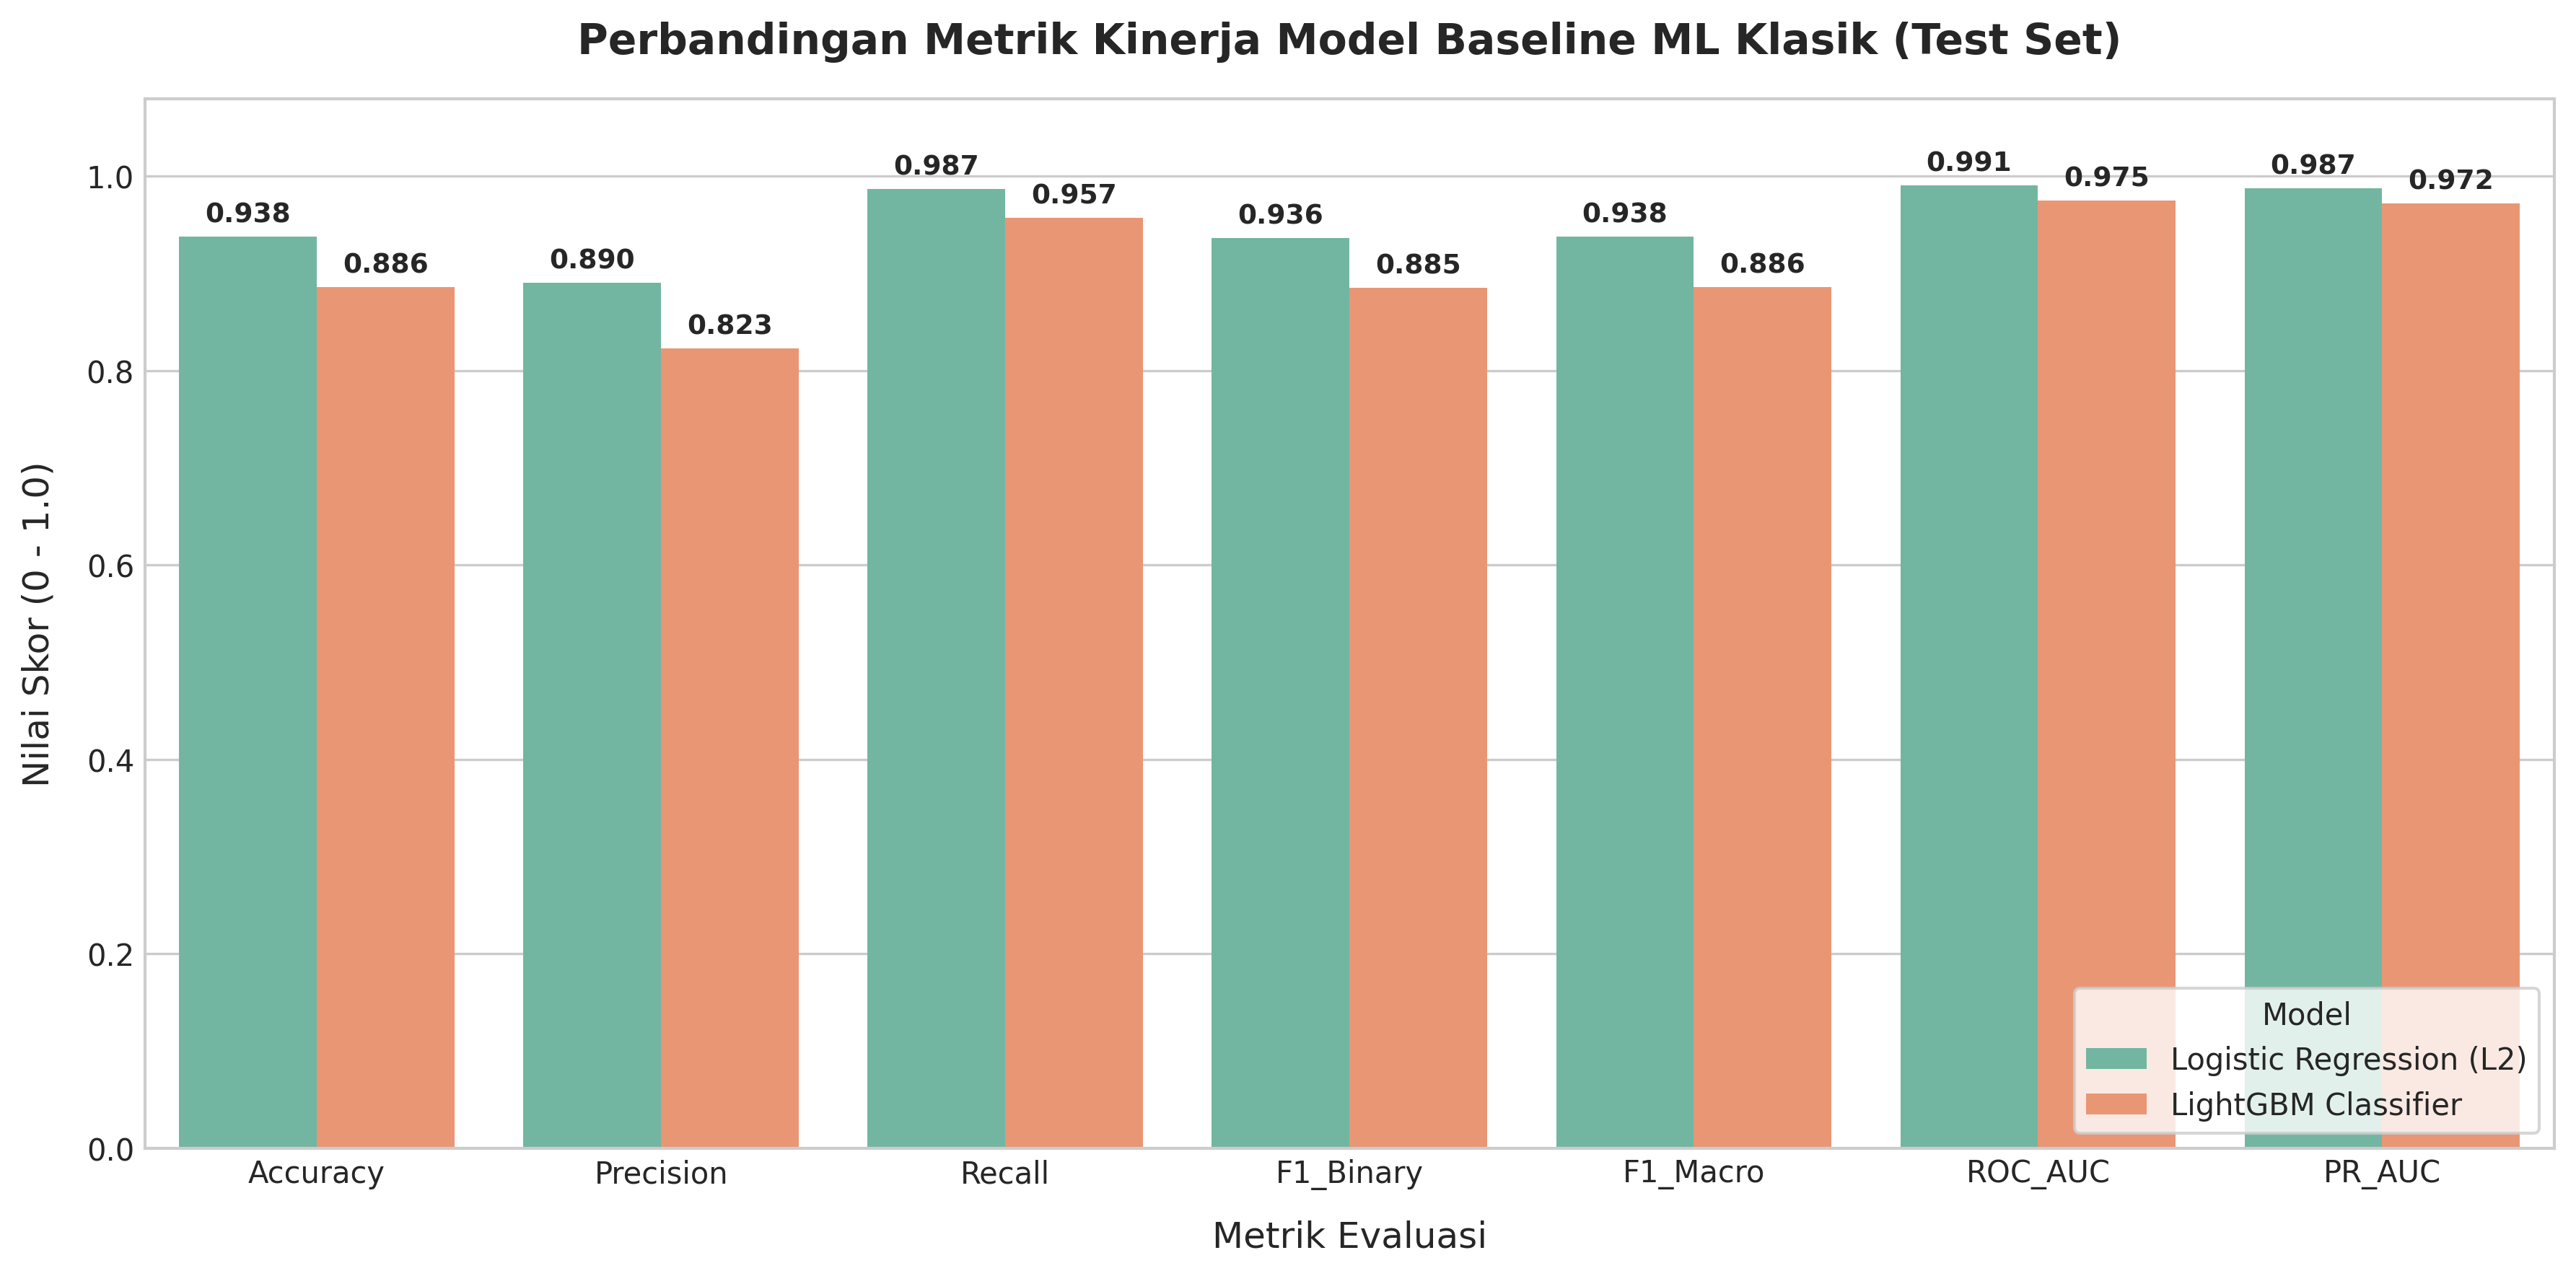

✅ Bar chart tersimpan: /content/drive/MyDrive/Skripsi/results/baseline_performance_bars.png


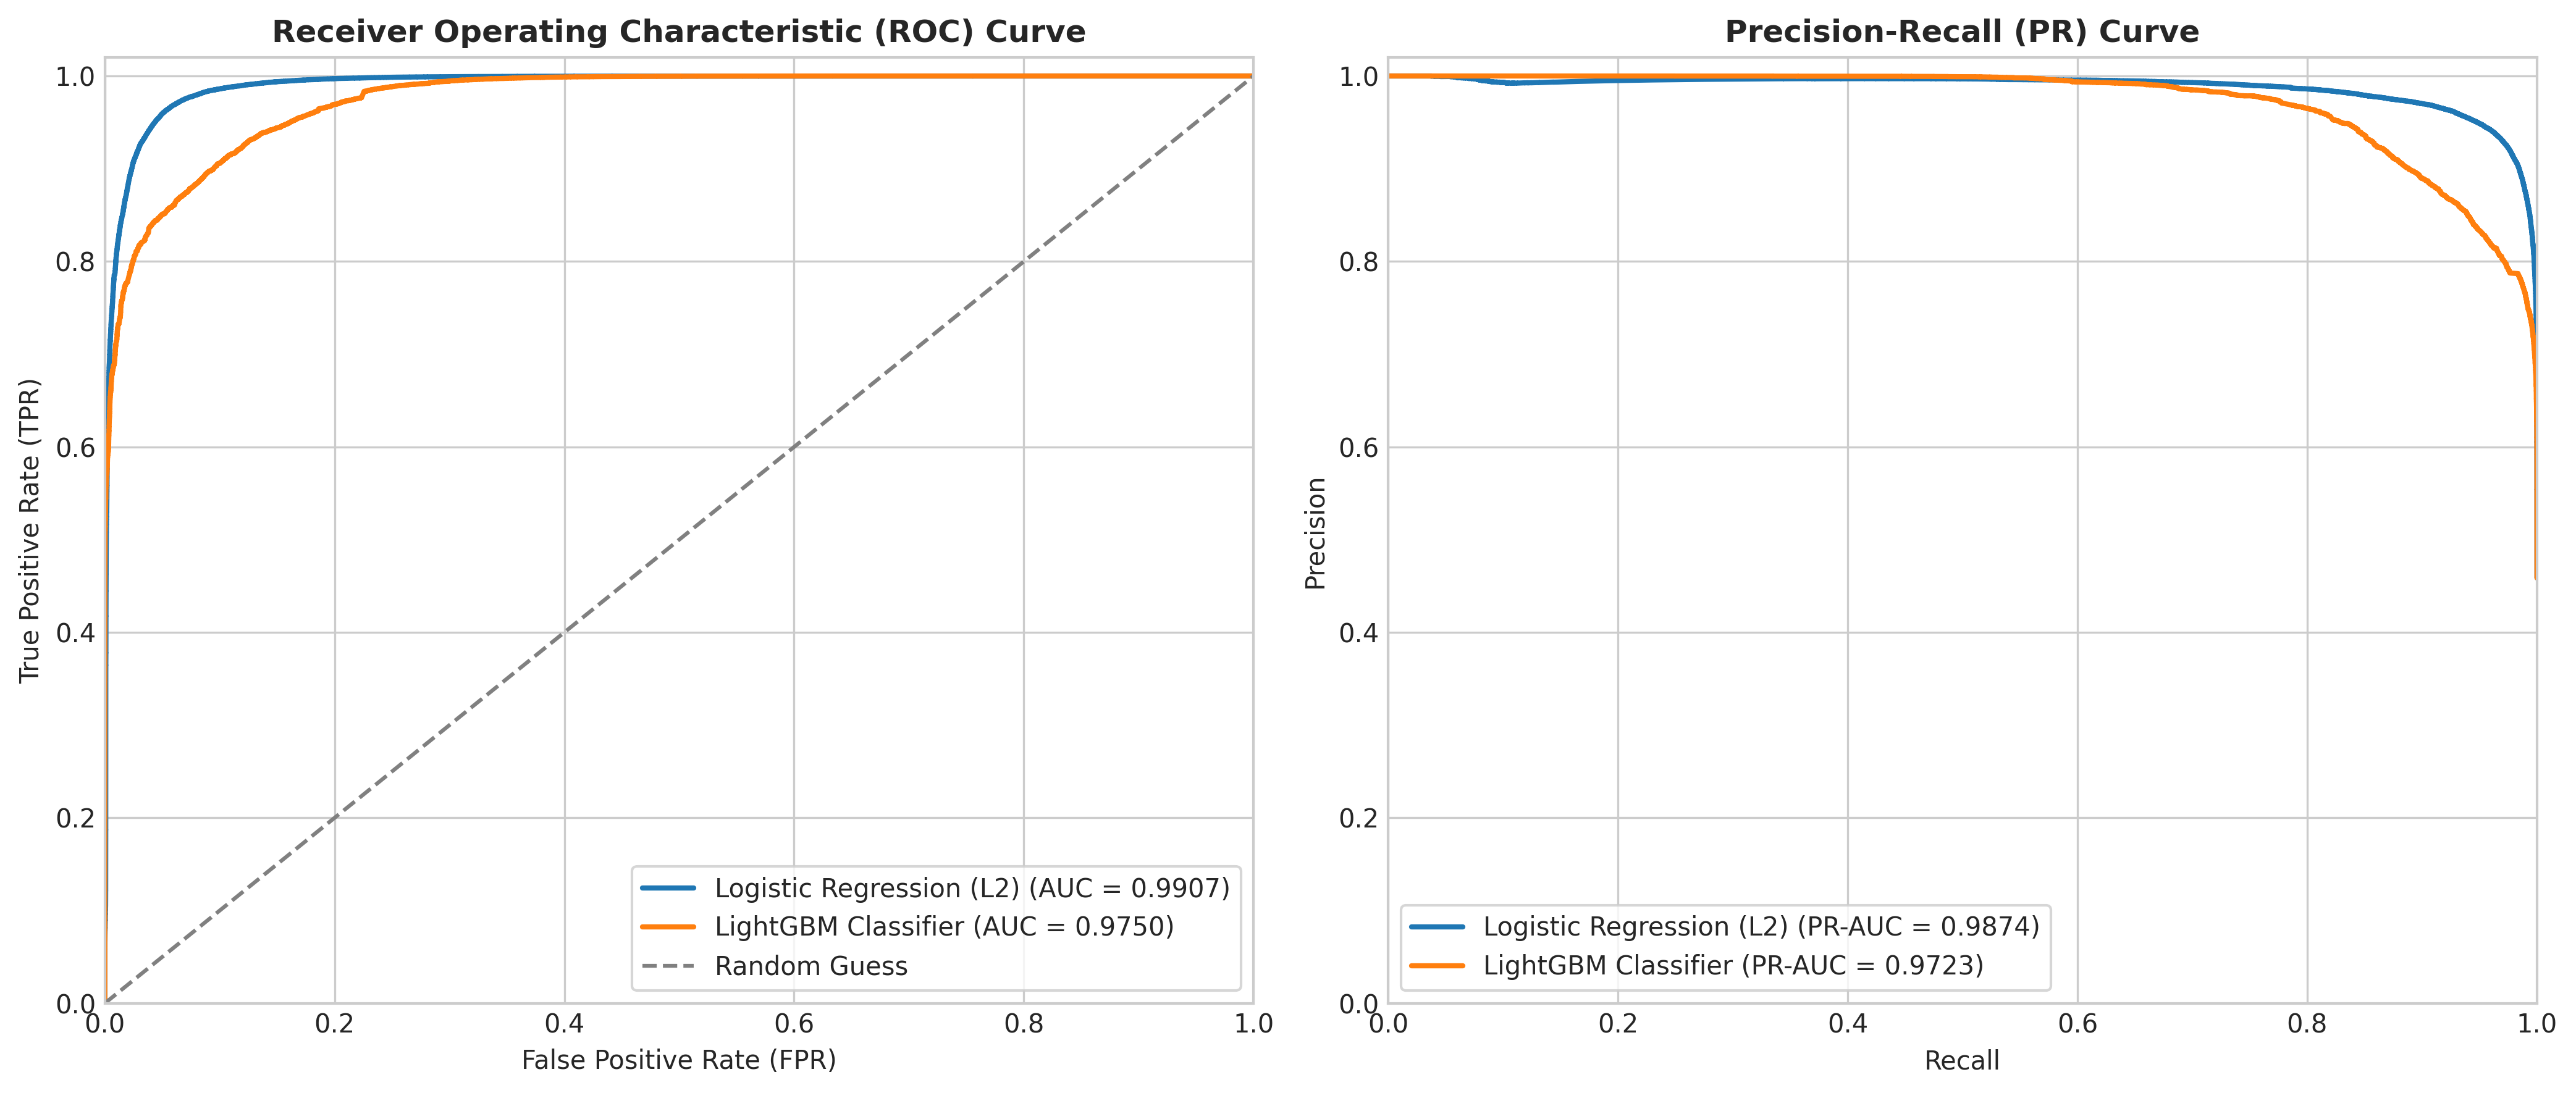

✅ ROC & PR curves tersimpan: /content/drive/MyDrive/Skripsi/results/baseline_roc_pr_curves.png


In [8]:
print("[INFO] Membuat visualisasi komparatif 300 DPI...")

# 1. Bar Chart Performa
metrics_names = ['Accuracy', 'Precision', 'Recall', 'F1_Binary', 'F1_Macro', 'ROC_AUC', 'PR_AUC']
df_melted = results_df.melt(id_vars=['Model'], value_vars=metrics_names, var_name='Metric', value_name='Score')

fig, ax = plt.subplots(figsize=(12, 6), dpi=300)
palette = sns.color_palette("Set2", n_colors=len(results_df))
sns.barplot(data=df_melted, x='Metric', y='Score', hue='Model', palette=palette, ax=ax)
ax.set_ylim(0, 1.08)
ax.set_title("Perbandingan Metrik Kinerja Model Baseline ML Klasik (Test Set)", fontsize=14, weight='bold', pad=15)
ax.set_xlabel("Metrik Evaluasi", fontsize=12, labelpad=10)
ax.set_ylabel("Nilai Skor (0 - 1.0)", fontsize=12, labelpad=10)
ax.legend(title="Model", frameon=True, loc='lower right')

for p in ax.patches:
    val = p.get_height()
    if val > 0:
        ax.annotate(f"{val:.3f}", (p.get_x() + p.get_width() / 2., val),
                    ha='center', va='bottom', fontsize=9, xytext=(0, 3),
                    textcoords='offset points', weight='semibold')

plt.tight_layout()
bar_plot_path = os.path.join(RESULTS_DIR, "baseline_performance_bars.png")
plt.savefig(bar_plot_path, dpi=300)
plt.show()
print(f"✅ Bar chart tersimpan: {bar_plot_path}")

# 2. Kurva ROC dan Kurva PR Berdampingan
fig, (ax_roc, ax_pr) = plt.subplots(1, 2, figsize=(14, 6), dpi=300)
colors = ['#1f77b4', '#ff7f0e']

for (m_name, m_data), color in zip(evaluation_data.items(), colors):
    # ROC
    fpr, tpr, _ = roc_curve(y_test, m_data['y_probs'])
    ax_roc.plot(fpr, tpr, color=color, lw=2, label=f"{m_name} (AUC = {m_data['roc_auc']:.4f})")

    # PR
    prec_vals, rec_vals, _ = precision_recall_curve(y_test, m_data['y_probs'])
    ax_pr.plot(rec_vals, prec_vals, color=color, lw=2, label=f"{m_name} (PR-AUC = {m_data['pr_auc']:.4f})")

ax_roc.plot([0, 1], [0, 1], color='gray', linestyle='--', lw=1.5, label='Random Guess')
ax_roc.set_title("Receiver Operating Characteristic (ROC) Curve", fontsize=12, weight='bold')
ax_roc.set_xlabel("False Positive Rate (FPR)", fontsize=10)
ax_roc.set_ylabel("True Positive Rate (TPR)", fontsize=10)
ax_roc.legend(loc='lower right', frameon=True)
ax_roc.set_xlim([0.0, 1.0])
ax_roc.set_ylim([0.0, 1.02])

ax_pr.set_title("Precision-Recall (PR) Curve", fontsize=12, weight='bold')
ax_pr.set_xlabel("Recall", fontsize=10)
ax_pr.set_ylabel("Precision", fontsize=10)
ax_pr.legend(loc='lower left', frameon=True)
ax_pr.set_xlim([0.0, 1.0])
ax_pr.set_ylim([0.0, 1.02])

plt.tight_layout()
curves_path = os.path.join(RESULTS_DIR, "baseline_roc_pr_curves.png")
plt.savefig(curves_path, dpi=300)
plt.show()
print(f"✅ ROC & PR curves tersimpan: {curves_path}")


## 9. Ekspor Hasil Evaluasi ke Google Drive
Menyimpan tabel ringkasan perbandingan model ke `/content/drive/MyDrive/Skripsi/results/baseline_comparison.csv`.


In [9]:
print(f"[INFO] Mengekspor hasil komparasi ke: {OUTPUT_CSV_PATH}...")
results_df.to_csv(OUTPUT_CSV_PATH, index=False)

file_size_kb = os.path.getsize(OUTPUT_CSV_PATH) / 1024
print(f"✅ [SUKSES] File berhasil disimpan: {OUTPUT_CSV_PATH} ({file_size_kb:.2f} KB)")

print("\n=== RINGKASAN AKHIR BASELINE BENCHMARK ===")
for _, r in results_df.iterrows():
    print(f"📌 {r['Model']:<25}: F1={r['F1_Binary']:.4f} | ROC-AUC={r['ROC_AUC']:.4f} | Latency={r['Latency_ms_per_sample']:.4f} ms | Throughput={r['Throughput_samples_per_s']:,.0f} samples/s")

print("\n🚀 [SELESAI] File 2: 02_Baseline_ML.ipynb berhasil dieksekusi dengan sempurna!")


[INFO] Mengekspor hasil komparasi ke: /content/drive/MyDrive/Skripsi/results/baseline_comparison.csv...
✅ [SUKSES] File berhasil disimpan: /content/drive/MyDrive/Skripsi/results/baseline_comparison.csv (0.31 KB)

=== RINGKASAN AKHIR BASELINE BENCHMARK ===
📌 Logistic Regression (L2) : F1=0.9361 | ROC-AUC=0.9907 | Latency=0.0012 ms | Throughput=857,009 samples/s
📌 LightGBM Classifier      : F1=0.8849 | ROC-AUC=0.9750 | Latency=0.0123 ms | Throughput=81,597 samples/s

🚀 [SELESAI] File 2: 02_Baseline_ML.ipynb berhasil dieksekusi dengan sempurna!
